<a href="https://colab.research.google.com/github/Saransh-Basu-01/50-Ml-Projects-to-understand-LLMs/blob/main/Project_35_Raw_and_Softmax_attention_scores.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:

import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

import torch
from transformers import AutoModelForCausalLM, GPT2Tokenizer
import torch.nn.functional as F

# Part 1: The reason to scale by sqrt(d_h)

## Task_1:
- In a for-loop over integers from N = 5 to N = 100, create two
N ×N matrices of Gaussian random numbers, and multiply them
together. Use standard matrix multiplication with the @ symbol, not
element-wise multiplication with the * symbol.
Create a second matrix defined as the product matrix scaled
by √N. Calculate and plot the standard deviations as in Figure
6.20. Then draw a line corresponding to the square root of the
matrix sizes.

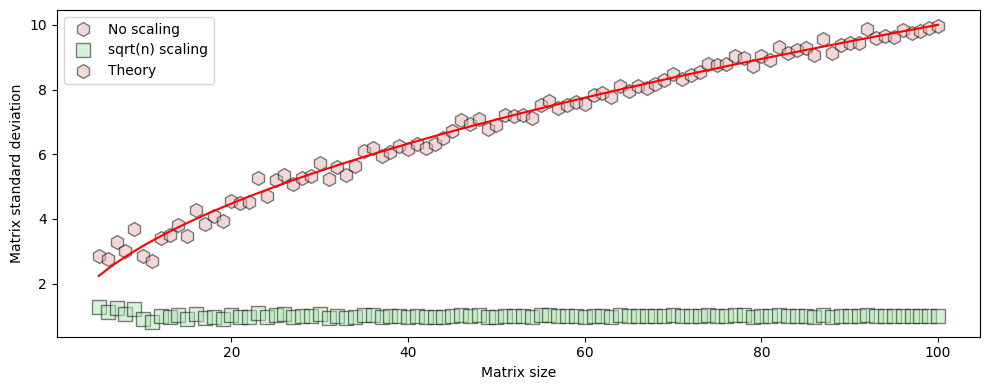

In [11]:

matsizes = np.arange(5,101)

plt.figure(figsize=(10,4))

for n in matsizes:

  # create the matrices
  M1 = np.random.randn(n,n) @ np.random.randn(n,n)
  M2 = M1 / np.sqrt(n)

  # plot
  plt.plot(n,M1.std(),'kh',markerfacecolor=[.9,.7,.7,.5],markersize=10)
  plt.plot(n,M2.std(),'ks',markerfacecolor=[.7,.9,.7,.5],markersize=10)



plt.plot(matsizes,np.sqrt(matsizes),'r')
plt.gca().set(xlabel='Matrix size',ylabel='Matrix standard deviation')
plt.legend(['No scaling','sqrt(n) scaling','Theory'])

plt.tight_layout()
plt.show()

# Part_2:Model,tokens,QKV Activations

## Task_1:
- Import GPT-2-medium. Implant a hook function into the c_attn
layer of transformer 6, that stores the activations in a dictionary.
Store the hook handle so it can be removed later.
Tokenize the text about the color purple that is in the online
code file. Push the tokens through the model and confirm that the
size of the attention activations is 1 × 115 × 3072

In [12]:
# load GPT2 model and tokenizer
model = AutoModelForCausalLM.from_pretrained('gpt2-medium')
tokenizer = GPT2Tokenizer.from_pretrained('gpt2')

model.eval()

config.json:   0%|          | 0.00/718 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.52GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/292 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

GPT2LMHeadModel(
  (transformer): GPT2Model(
    (wte): Embedding(50257, 1024)
    (wpe): Embedding(1024, 1024)
    (drop): Dropout(p=0.1, inplace=False)
    (h): ModuleList(
      (0-23): 24 x GPT2Block(
        (ln_1): LayerNorm((1024,), eps=1e-05, elementwise_affine=True, bias=True)
        (attn): GPT2Attention(
          (c_attn): Conv1D(nf=3072, nx=1024)
          (c_proj): Conv1D(nf=1024, nx=1024)
          (attn_dropout): Dropout(p=0.1, inplace=False)
          (resid_dropout): Dropout(p=0.1, inplace=False)
        )
        (ln_2): LayerNorm((1024,), eps=1e-05, elementwise_affine=True, bias=True)
        (mlp): GPT2MLP(
          (c_fc): Conv1D(nf=4096, nx=1024)
          (c_proj): Conv1D(nf=1024, nx=4096)
          (act): NewGELUActivation()
          (dropout): Dropout(p=0.1, inplace=False)
        )
      )
    )
    (ln_f): LayerNorm((1024,), eps=1e-05, elementwise_affine=True, bias=True)
  )
  (lm_head): Linear(in_features=1024, out_features=50257, bias=False)
)

In [13]:
# hook the attention vectors
activations = {}

def hook(module,input,output):
  activations[keyName] = output.detach()

# implant the hooks
whichlayer = 6
keyName = f'attn_{whichlayer}'
hookhandle = model.transformer.h[whichlayer].attn.c_attn.register_forward_hook(hook)

In [25]:
# https://en.wikipedia.org/wiki/Purple
txt = "Purple is a color similar in appearance to violet light. In the RYB color model historically used in the arts, purple is a secondary color created by combining red and blue pigments. In the CMYK color model used in modern printing, purple is made by combining magenta pigment with either cyan pigment, black pigment, or both. In the RGB color model used in computer and television screens, purple is created by mixing red and blue light in order to create colors that appear similar to violet light. According to color theory, purple is considered a cool color."

# tokenize
tokens = tokenizer.encode(txt,return_tensors='pt')
ntokens =len(tokens[0])

# run through the model
with torch.no_grad():
  model(tokens)

In [26]:

# checking sizes
print(activations.keys())
print(activations[keyName].shape)

dict_keys(['attn_6'])
torch.Size([1, 115, 3072])


In [27]:
activations

{'attn_6': tensor([[[ 0.2274,  0.1474,  0.0110,  ...,  0.0260,  0.0559,  0.0257],
          [-0.4611, -1.7914,  0.2417,  ...,  0.1127,  0.6776, -0.7316],
          [ 0.0039, -0.1152, -0.5475,  ...,  0.4973, -0.2862, -1.3271],
          ...,
          [ 0.4443, -0.2666,  1.3602,  ...,  0.5379,  0.5546,  0.2758],
          [ 1.7429, -0.8359,  0.8308,  ..., -0.4077,  0.4291,  0.4087],
          [ 0.1460,  0.1959,  1.2098,  ..., -0.5595,  0.0646,  0.8506]]])}

In [20]:
model.transformer.h[6].attn.c_attn

Conv1D(nf=3072, nx=1024)

# Part 3: Split into heads

## Task_1:
- Define variables for the number of layers, the embeddings dimen
sionality, the number of heads, the head dimensionality, and √dh.
Confirm that there are 16 heads, each with 64 dimensions.
Separate the activations matrix from Part 2 into the queries,
keys, and values matrices, and then split the Q and K matrices
further into lists of heads.
Show the activations heatmaps from all Q heads as in Figure
6.21. The x-axis shows token positions and the y-axis shows the
head dimensionality. This is similar to the figure from Project 34
but you’ll need to modify the code to account for the different data
organization

In [28]:

# some helpful variables
n_layers = model.config.n_layer
n_emb = model.config.n_embd
n_heads = model.config.n_head
head_dim = model.config.n_embd //n_heads
sqrtD =head_dim ** .5

print(f'There are {n_heads} heads, each with {head_dim} dimensions.')

There are 16 heads, each with 64 dimensions.


In [31]:
activations[keyName]

tensor([[[ 0.2274,  0.1474,  0.0110,  ...,  0.0260,  0.0559,  0.0257],
         [-0.4611, -1.7914,  0.2417,  ...,  0.1127,  0.6776, -0.7316],
         [ 0.0039, -0.1152, -0.5475,  ...,  0.4973, -0.2862, -1.3271],
         ...,
         [ 0.4443, -0.2666,  1.3602,  ...,  0.5379,  0.5546,  0.2758],
         [ 1.7429, -0.8359,  0.8308,  ..., -0.4077,  0.4291,  0.4087],
         [ 0.1460,  0.1959,  1.2098,  ..., -0.5595,  0.0646,  0.8506]]])

In [35]:

# first, separate the Q,K,V matrices
Q,K,V = torch.split(activations[keyName][0,:,:],n_emb,dim=1)
Q.shape

torch.Size([115, 1024])

In [36]:
# now split into heads
Q_h = torch.split(Q,head_dim,dim=1)
K_h = torch.split(K,head_dim,dim=1)

print(f'There are {len(Q_h)} heads')
print(f'Each head has size {Q_h[2].shape}')

There are 16 heads
Each head has size torch.Size([115, 64])


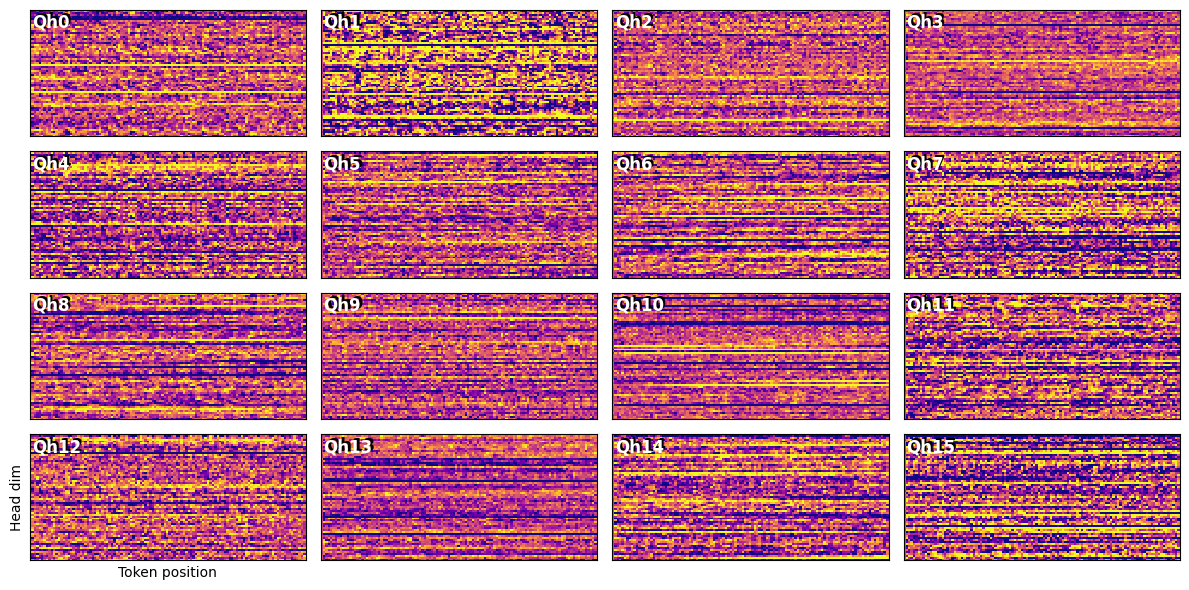

In [43]:

# visualize
_,axs = plt.subplots(4,4,figsize=(12,6))

for i,ax in enumerate(axs.flatten()):
  ax.pcolor(Q_h[i].T,cmap='plasma',vmin=-2,vmax=2)
  ax.text(2,head_dim-1,f'Qh{i}',fontsize=12,fontweight='bold',color='k',ha='left',va='top')
  ax.text(1,head_dim-2,f'Qh{i}',fontsize=12,fontweight='bold',color='w',ha='left',va='top')
  ax.set(xticks=[],yticks=[])

# finalize
axs[3,0].set(ylabel='Head dim',xlabel='Token position')

plt.tight_layout()
plt.show()